# Tap-test inversion: cable layout and hammer locations

Draws the DAS cable over a Planet satellite scene, together with every hammer
(tap-test) location that went into the batch inversion, and the cable aperture
each event used.

Sources
- cable geometry: `data/channel_geometry_20260908.npz` (`ch_latlon` of every
  channel) -- the same geometry
  `main_preprocess.ipynb` indexes when it builds the f-k curves.
- events: `outputs/tap_inv_batch/dispersion_events_0908.npz`, whose metadata carries each hammer's
  lat/lon, timestamp, and the channel window (`start_idx`, `end_idx`,
  `ch_offset`) used per wave type.
- basemap: `data/satellite/...visual_clip.tif`.

Basemap, lat/lon axes and scale bar come from `das_tools.maps`, as in the
fieldwork-context figures.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D

from das_tools import maps
from das_tools.utils import proj_path

In [2]:
# ============================================================
# User settings
# ============================================================

TITLE_FONTSIZE = 18
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 14
LEGEND_FONTSIZE = 12
PANEL_LABEL_FONTSIZE = 18

mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.size": LABEL_FONTSIZE,
    "axes.titlesize": TITLE_FONTSIZE,
    "axes.labelsize": LABEL_FONTSIZE,
    "xtick.labelsize": TICK_FONTSIZE,
    "ytick.labelsize": TICK_FONTSIZE,
    "legend.fontsize": LEGEND_FONTSIZE,
})

DATA_ROOT = proj_path.data_dir()

GEOTIFF_PATH = DATA_ROOT / "satellite" / "20250503_050318_ssc4_u0001_visual_clip.tif"

# Cable geometry used by main_preprocess.ipynb -> dispersion_events_0908.npz.
CHANNEL_GEOMETRY_PATH = DATA_ROOT / "channel_geometry_20260908.npz"

# Event set that was inverted. Swap for "dispersion_events.npz" to plot the
# earlier batch (same schema, same hammer metadata).
EVENTS_PATH = proj_path.output_dir("tap_inv_batch", "dispersion_events_0908.npz")

# Map ROI, expressed as a half-box in km about the cable's western-most point
# (same construction as the fieldwork-context figure).
HALF_SIZE_KM_LAT = 0.6
HALF_SIZE_KM_LON = 0.6

# Channel span carrying tap-test events, padded; used to frame the zoomed view.
ACTIVE_CHANNEL_PADDING = 10

# One colour for every acquisition date: the dates are distinguished in the
# text, not the figure, so a single marker style keeps the map readable.
HAMMER_COLOR = "yellow"

LABEL_EVENT_IDS = True          # annotate each hammer with its event id(s)
EVENT_LABEL_OFFSET_M = 11.0     # label offset from the marker, in map metres
DRAW_APERTURES = False          # draw the cable span each event beamformed over

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
OUT_PNG = FIGURE_DIR / "tap_test_cable_layout_hammers.png"
OUT_PDF = FIGURE_DIR / "tap_test_cable_layout_hammers.pdf"

In [3]:
# ============================================================
# Load cable geometry and events
# ============================================================

def load_cable_lonlat(geometry_path: Path):
    """Lon/lat of every channel, plus its local-metre ch_xy, from the geometry file."""
    geo = np.load(geometry_path)
    lat, lon = geo["ch_latlon"]
    return np.asarray(lon, float), np.asarray(lat, float), geo["ch_xy"]


def load_events(events_path: Path):
    """Flatten the event metadata into one record per event.

    Each record keeps the hammer lat/lon, the timestamp, the wave types that
    survived picking, and the union of the channel windows over those waves
    (the aperture the event actually saw).
    """
    npz = np.load(events_path, allow_pickle=True)
    meta = json.loads(str(npz["metadata"]))

    records = []
    for entry in meta["events"]:
        emeta = entry["metadata"]
        waves = entry["waves"]

        windows = []
        for wave_name, wave in waves.items():
            wmeta = wave["metadata"]
            off = int(wmeta.get("ch_offset", 0))
            windows.append({
                "wave": wave_name,
                "ch_start": int(wmeta["start_idx"]) + off,
                "ch_end": int(wmeta["end_idx"]) + off,
                "d1": float(wmeta["window"]["d1"]),
                "d2": float(wmeta["window"]["d2"]),
            })

        records.append({
            "event_id": int(entry["event_id"]),
            "timestamp": emeta["timestamp"],
            "date": emeta["timestamp"][:10],
            "lat": float(emeta["lat"]),
            "lon": float(emeta["lon"]),
            "waves": sorted(waves.keys()),
            "windows": windows,
            "ch_start": min(w["ch_start"] for w in windows),
            "ch_end": max(w["ch_end"] for w in windows),
            "d1": min(w["d1"] for w in windows),
            "d2": max(w["d2"] for w in windows),
        })

    return records


def group_by_hammer(records, tol_deg=1e-6):
    """Several events share one hammer strike; collapse them onto one marker."""
    sites = []
    for rec in records:
        for site in sites:
            if (abs(site["lat"] - rec["lat"]) < tol_deg
                    and abs(site["lon"] - rec["lon"]) < tol_deg):
                site["event_ids"].append(rec["event_id"])
                site["waves"].update(rec["waves"])
                break
        else:
            sites.append({
                "lat": rec["lat"],
                "lon": rec["lon"],
                "date": rec["date"],
                "timestamp": rec["timestamp"],
                "event_ids": [rec["event_id"]],
                "waves": set(rec["waves"]),
            })
    return sites


cab_lon, cab_lat, ch_xy = load_cable_lonlat(CHANNEL_GEOMETRY_PATH)
events = load_events(EVENTS_PATH)
hammer_sites = group_by_hammer(events)

print(f"cable: {cab_lon.size} channels")
print(f"events: {len(events)}  |  distinct hammer locations: {len(hammer_sites)}")
print()
print(f"{'ev':>3}  {'timestamp':<26} {'lat':>10} {'lon':>12}  {'ch span':>11}  "
      f"{'distance (m)':>15}  waves")
for rec in events:
    print(f"{rec['event_id']:>3}  {rec['timestamp']:<26} {rec['lat']:>10.6f} "
          f"{rec['lon']:>12.6f}  {rec['ch_start']:>4d}-{rec['ch_end']:<4d}  "
          f"{rec['d1']:>6.0f}-{rec['d2']:<6.0f}  {','.join(rec['waves'])}")

cable: 655 channels
events: 23  |  distinct hammer locations: 16

 ev  timestamp                         lat          lon      ch span     distance (m)  waves
  0  2025-04-24T00:25:10.274900  71.347242  -156.676334   470-586     1500-1870    FG,P
  1  2025-04-24T00:25:10.274900  71.347242  -156.676334   586-643     1870-2050    FG,P
  2  2025-04-24T00:27:36.894900  71.347604  -156.674354   470-611     1500-1950    FG,P,SH
  3  2025-04-24T00:27:36.894900  71.347604  -156.674354   611-643     1950-2050    FG,P
  4  2025-04-24T00:30:26.576900  71.348027  -156.671874   486-643     1550-2050    FG,P,SH
  5  2025-04-24T21:55:00         71.344379  -156.673297   487-594     1580-1920    FG,P
  6  2025-04-24T21:58:46         71.344870  -156.674066   501-594     1625-1920    FG,P
  7  2025-04-24T21:58:46         71.344870  -156.674066   462-501     1500-1625    FG,P
  8  2025-04-24T21:59:38         71.345023  -156.674326   514-603     1665-1950    FG
  9  2025-04-24T22:47:27         71.345271  -

In [4]:
# ============================================================
# Basemap
# ============================================================

def prepare_basemap(cab_lon, cab_lat):
    """Satellite ROI about the cable's western-most point (as in the fieldwork-context figure).

    The cable runs north-east of that point, so only half the box extends
    west and south of it.
    """
    i0 = int(np.argmin(cab_lon))
    lon0, lat0 = float(cab_lon[i0]), float(cab_lat[i0])
    lon_w, lon_e, lat_s, lat_n = maps.lonlat_box(lon0, lat0, HALF_SIZE_KM_LON, HALF_SIZE_KM_LAT)
    return maps.load_basemap(
        GEOTIFF_PATH,
        lon0 - 0.5 * (lon0 - lon_w), lon_e, lat_s, lat0 + 0.5 * (lat_n - lat0),
        stretch=(0, 90),
    )

In [5]:
# ============================================================
# Map panel
# ============================================================

# Candidate label placements, in units of EVENT_LABEL_OFFSET_M, tried in order
# until one lands clear of the labels already placed.
_LABEL_OFFSETS = [(1, 1), (-1, 1), (1, -1), (-1, -1),
                  (0, 1.4), (0, -1.4), (1.6, 0), (-1.6, 0),
                  (2.2, 1.4), (-2.2, 1.4), (2.2, -1.4), (-2.2, -1.4)]


def place_labels_without_overlap(ax, labels):
    """Nudge event-id labels onto the first candidate offset that stays clear.

    ``labels`` is a list of ``(text_artist, x, y)`` in data coordinates. Overlap
    is measured in display space, so the result follows the axes limits.
    """
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    placed = []
    for txt, x, y in labels:
        best = None
        for fx, fy in _LABEL_OFFSETS:
            txt.set_position((x + fx * EVENT_LABEL_OFFSET_M,
                              y + fy * EVENT_LABEL_OFFSET_M))
            txt.set_ha("left" if fx >= 0 else "right")
            txt.set_va("bottom" if fy >= 0 else "top")
            bb = txt.get_window_extent(renderer=renderer).expanded(1.05, 1.15)
            if not any(bb.overlaps(other) for other in placed):
                best = bb
                break
        if best is None:
            best = txt.get_window_extent(renderer=renderer)
        placed.append(best)


def plot_cable_and_hammers(ax, base, zoom_to_events=False):
    x_cab, y_cab = base.xy(cab_lon, cab_lat)
    x_hm, y_hm = base.xy([s["lon"] for s in hammer_sites], [s["lat"] for s in hammer_sites])

    if zoom_to_events:
        # Frame the channels that carried events, and every hammer.
        lo = max(min(r["ch_start"] for r in events) - ACTIVE_CHANNEL_PADDING, 0)
        hi = min(max(r["ch_end"] for r in events) + ACTIVE_CHANNEL_PADDING, x_cab.size - 1)
        xs = np.r_[x_cab[lo:hi + 1], x_hm]
        ys = np.r_[y_cab[lo:hi + 1], y_hm]
        pad = 0.12 * max(np.ptp(xs), np.ptp(ys))
        lon_box, lat_box = base.lonlat([xs.min() - pad, xs.max() + pad],
                                       [ys.min() - pad, ys.max() + pad])
        base = base.crop(lon_box.min(), lon_box.max(), lat_box.min(), lat_box.max())
    base.show(ax)

    # Whole cable, one heavy red line.
    ax.plot(x_cab, y_cab, color="r", linewidth=5, zorder=6, label="Cable",
            path_effects=maps.halo(9, "black"))

    # Per-event apertures, stacked as faint parallel overlays on the cable.
    if DRAW_APERTURES:
        for rec in events:
            a, b = rec["ch_start"], rec["ch_end"]
            ax.plot(x_cab[a:b + 1], y_cab[a:b + 1],
                    color="white", linewidth=1.2, alpha=0.55,
                    solid_capstyle="butt", zorder=7)

    # Hammer locations: same marker for every date.
    labels = []
    for site, xh, yh in zip(hammer_sites, x_hm, y_hm):
        ax.scatter(xh, yh, s=170, marker="^", color=HAMMER_COLOR,
                   edgecolors="k", linewidths=1.2, zorder=9)
        if LABEL_EVENT_IDS:
            ids = ",".join(str(i) for i in sorted(site["event_ids"]))
            txt = ax.text(xh, yh, ids, ha="left", va="bottom", fontsize=10, color="k",
                          zorder=10, path_effects=maps.halo(2.5))
            labels.append((txt, xh, yh))

    maps.add_scalebar(ax, base, 200, corner="lower left", pad=(0.08, 0.05), fontsize=16)
    secax_x, secax_y = maps.add_lonlat_axes(ax, base, lon_step=0.005, lat_step=0.002,
                                            lon_decimals=3, lat_decimals=3)
    secax_x.tick_params(axis="x", labelsize=TICK_FONTSIZE)
    secax_y.tick_params(axis="y", labelsize=TICK_FONTSIZE)

    handles = [
        Line2D([], [], color="r", linewidth=4, label="Cable"),
        Line2D([], [], marker="^", linestyle="none", markersize=11,
               markerfacecolor=HAMMER_COLOR, markeredgecolor="k",
               label="Hammer location"),
    ]
    ax.legend(handles=handles, loc="upper left", ncol=1,
              borderpad=0.6, handletextpad=0.6, columnspacing=1.2,
              framealpha=0.9, fontsize=LEGEND_FONTSIZE).set_zorder(12)

    # Labels are placed last: the axes limits and legend are settled by now.
    if LABEL_EVENT_IDS:
        place_labels_without_overlap(ax, labels)

    return ax


In [6]:
# ============================================================
# Aperture panel: which cable span each event beamformed over
# ============================================================

WAVE_COLORS = {"FG": "#0072b2", "P": "#d55e00", "SH": "#009e73"}


# Wave types share a row, so give each its own sub-row offset; otherwise a
# narrow SH window disappears under the P window that covers it.
WAVE_ORDER = ["FG", "P", "SH"]
WAVE_ROW_OFFSET = {"FG": -0.22, "P": 0.0, "SH": 0.22}


def plot_apertures(ax):
    for row, rec in enumerate(events):
        for w in sorted(rec["windows"],
                        key=lambda w: WAVE_ORDER.index(w["wave"])
                        if w["wave"] in WAVE_ORDER else len(WAVE_ORDER)):
            y = row + WAVE_ROW_OFFSET.get(w["wave"], 0.0)
            ax.plot([w["d1"], w["d2"]], [y, y],
                    color=WAVE_COLORS.get(w["wave"], "k"),
                    linewidth=4, solid_capstyle="butt", alpha=0.95,
                    zorder=3)

    ax.set_yticks(range(len(events)))
    ax.set_yticklabels([f"{r['event_id']} ({r['date'][5:]})" for r in events],
                       fontsize=11)
    ax.invert_yaxis()
    ax.set_xlabel("Channel distance (m)", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("Event (date)", fontsize=LABEL_FONTSIZE)
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="x", labelsize=TICK_FONTSIZE)

    handles = [Line2D([], [], color=c, linewidth=5, label=w)
               for w, c in WAVE_COLORS.items()]
    ax.legend(handles=handles, loc="lower right", fontsize=LEGEND_FONTSIZE,
              framealpha=0.9, title="Wave", title_fontsize=LEGEND_FONTSIZE)
    return ax

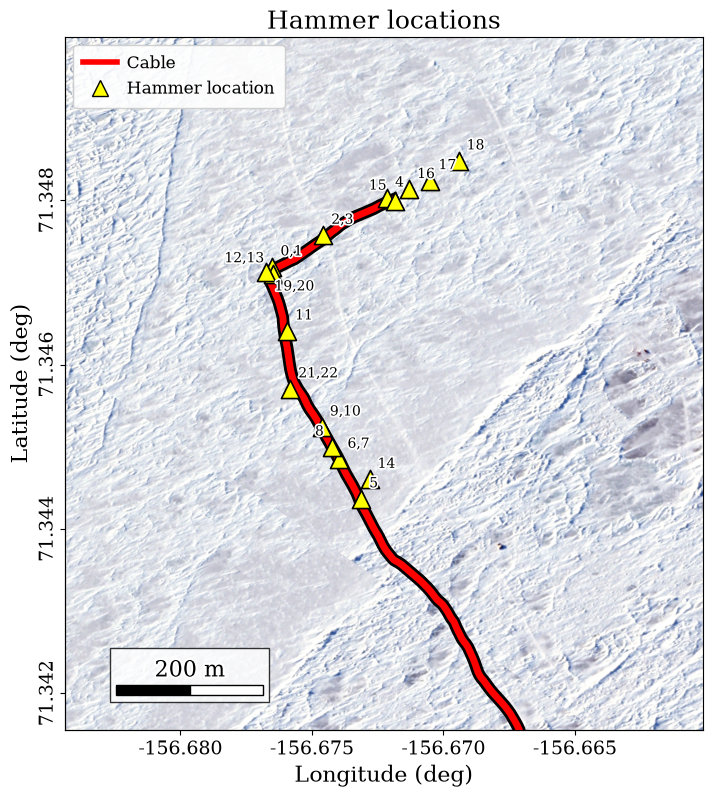

In [8]:
base = prepare_basemap(cab_lon, cab_lat)

fig2, ax2 = plt.subplots(figsize=(9, 9))
plot_cable_and_hammers(ax2, base, zoom_to_events=False)
ax2.set_title("Hammer locations", fontsize=TITLE_FONTSIZE)
fig2.savefig(FIGURE_DIR / "tap_test_cable_layout_hammers_wide.pdf",
             dpi=300, bbox_inches="tight")
plt.show()